# Цена устойчивости: маршрутизация робота при сбоях привода

**Курсовое задание по обучению с подкреплением. Трек 2.**

Цель - проверить перенос табличного Q-learning на более ненадёжный привод.
Робот доставляет груз на небольшой сетке с опасной зоной. Короткий маршрут
проходит рядом с ней, а обход требует больше шагов.

План: описать и проверить среду -> зафиксировать протокол -> обучить два варианта
с пятью seed -> оценить их на отдельных эпизодах -> разобрать маршруты и ограничения.

## 1. Вопрос и протокол до обучения

**Вопрос.** Повышает ли обучение при 15% случайных поворотов действия надёжность
доставки при 30% таких сбоев, и какова цена устойчивости в отсутствие сбоев?

**Гипотеза.** Обучение со сбоями заставит агента выбирать маршрут с запасом до
опасной зоны. При $p=0.30$ средняя награда и доля доставок вырастут, но при $p=0$
путь может стать длиннее. Ответ при конечном бюджете не гарантирован:
обучение на шуме сложнее, а слишком осторожный агент может расходовать весь лимит.

**Единственный изменяемый фактор обучения** - вероятность сбоя: $p=0$ (`dry`)
или $p=0.15$ (`noisy`). Карта, награда, начальные позиции, алгоритм, гиперпараметры
и бюджет совпадают. Сбой - выполнение перпендикулярного действия, а не добавление
шума к наблюдению. Это обучение при фиксированной стохастической динамике,
без рандомизации параметров между эпизодами.

Основной критерий - разность средних недисконтированных наград при $p=0.30$,
усреднённая поровну по двум наборам стартов. Доля доставок проверяет практический смысл
изменения награды. Дополнительно измеряются аварии, таймауты, число шагов и доля
шагов рядом с опасной зоной. Цена устойчивости оценивается при $p=0$.

Пять seed обучения: `11, 23, 37, 53, 71`; бюджет - ровно 100 000 переходов на запуск.
После обучения замороженные жадные политики проверяются при
$p \in \{0, 0.05, 0.10, 0.15, 0.20, 0.30, 0.40\}$.
На каждую пару «уровень шума, набор стартов» выделено 60 эпизодов:
по 20 на каждую из трёх позиций. Seed теста общие для всех политик и отличаются от
seed обучения и промежуточной валидации. Тест не используется для выбора модели:
оценивается последний шаг, без подбора параметров по тесту.

## 2. Окружение и параметры

Запускать из каталога проекта с файлами `warehouse_env.py` и `experiment_config.json`.
В Colab достаточно загрузить эти два файла и ноутбук в одну папку. Установка
зависимостей описана в README; GPU не требуется. Ячейки выполняются сверху вниз.

In [1]:
import hashlib
import json
import platform
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from PIL import Image as PILImage
from gymnasium.utils.env_checker import check_env

PROJECT = Path.cwd()
if not (PROJECT / "experiment_config.json").exists():
    PROJECT = PROJECT / "3 sem" / "RL" / "course_task"
sys.path.insert(0, str(PROJECT.resolve()))
from warehouse_env import WarehouseEnv

CFG = json.loads((PROJECT / "experiment_config.json").read_text(encoding="utf-8"))
OUT = PROJECT / "results"
OUT.mkdir(exist_ok=True)
LABELS = {"dry": "Q: без сбоев", "noisy": "Q: обучение со сбоями",
          "random": "Случайная", "shortest": "Короткий путь", "safe": "Обход"}
COLORS = {"dry": "#dc7c39", "noisy": "#3167ad"}
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})
experiment_started = time.perf_counter()

## 3. Среда и смысл награды

Карта имеет 7 строк и 11 столбцов. Опасная зона - нижняя строка в столбцах 1-9,
цель - клетка `(6, 10)`. Наблюдение $s=11r+c$ однозначно задаёт координаты.
В каждом фиксированном условии это конечный MDP с 77 наблюдениями и четырьмя
действиями: вверх, вправо, вниз, влево. С вероятностью $p/2$ действие поворачивается
на 90 градусов влево и с вероятностью $p/2$ вправо; иначе выполняется как задумано.
Движение через границу оставляет робота на месте. Шум независим между шагами.

Награда за переход: $r=-1+30 I_{\text{цель}}-50 I_{\text{авария}}$.
Стоимость шага поощряет быструю доставку, бонус - достижение цели, штраф - избегание
опасной зоны. Это условная цена времени и потери груза; штраф не задаёт жёсткую
гарантию безопасности. Цель и авария завершают задачу (`terminated`). После 80 шагов
наблюдение обрывается внешним лимитом (`truncated`). Дополнительного штрафа за
таймаут нет. Этот лимит - ограничение эксперимента, а не часть наблюдаемого состояния.

Обучающие старты: `(6, 0), (5, 0), (4, 0)`. Второй набор:
`(3, 0), (2, 0), (2, 1)`. Он не используется как начальное распределение обучения,
но его клетки могут встречаться на обучающих траекториях. Поэтому это перенос
на другое начальное распределение на той же карте, без заявления об обобщении
на совершенно неизвестные состояния или новые карты.

Исходный код среды вынесен в `warehouse_env.py`. Отдельные тесты проверяют
конечные награды, границы, лимит, воспроизводимость и вероятности сбоя.

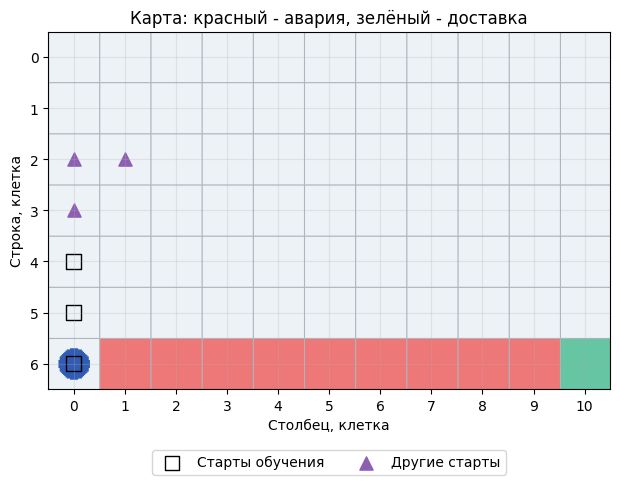

In [2]:
check_env(WarehouseEnv(), skip_render_check=True)
assert set(WarehouseEnv.train_starts).isdisjoint(WarehouseEnv.shifted_starts)
env = WarehouseEnv(render_mode="rgb_array")
env.reset(seed=0, options={"start": (6, 0)})

fig, ax = plt.subplots(figsize=(10, 5))
ax.imshow(env.render(), extent=(-0.5, 10.5, 6.5, -0.5))
ax.scatter(*zip(*[(c, r) for r, c in WarehouseEnv.train_starts]),
           marker="s", s=110, facecolors="none", edgecolors="black", label="Старты обучения")
ax.scatter(*zip(*[(c, r) for r, c in WarehouseEnv.shifted_starts]),
           marker="^", s=90, color="#8d5fb3", label="Другие старты")
ax.set(xticks=range(11), yticks=range(7), xlabel="Столбец, клетка",
       ylabel="Строка, клетка", title="Карта: красный - авария, зелёный - доставка")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
fig.tight_layout()
fig.savefig(OUT / "map.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Единая процедура оценки и простые стратегии

Случайная стратегия выбирает каждое действие с вероятностью 1/4. Эвристика
«короткий путь» идёт по строке 5 рядом с опасной зоной. «Обход» держится строки 3
до правого края, затем спускается к цели. Обе эвристики используют известную карту,
но не знают уровень шума; это понятные ориентиры, без утверждения об их оптимальности.

При оценке обучение и исследование действий отключены. Для одинакового seed среда
использует одну и ту же последовательность случайных чисел. Разные политики могут
попадать в разные клетки и завершаться в разные моменты, поэтому совпадают
случайные воздействия по номеру шага, а не полные траектории.

In [3]:
def choose_action(policy, observation, rng):
    row, col = divmod(observation, WarehouseEnv.cols)
    if isinstance(policy, np.ndarray):
        return int(np.argmax(policy[observation]))
    if policy == "random":
        return int(rng.integers(4))
    if col == 10:
        return 2  # Спускаемся к доставке вдоль правой границы.
    corridor = 5 if policy == "shortest" else 3
    if row > corridor:
        return 0
    if row < corridor:
        return 2
    return 1


def run_episode(policy, slip, start, seed):
    env = WarehouseEnv(slip=slip, max_steps=CFG["max_episode_steps"])
    observation, _ = env.reset(seed=seed, options={"start": start})
    rng = np.random.default_rng(seed + 10_000_000)
    total, adjacent = 0.0, 0
    path = [env.position]
    while True:
        row, col = env.position
        adjacent += int(row == 5 and 1 <= col <= 9)
        action = choose_action(policy, observation, rng)
        observation, reward, terminated, truncated, info = env.step(action)
        total += reward
        path.append(env.position)
        if terminated or truncated:
            return {"return": total, "success": int(info["success"]),
                    "hazard": int(info["hazard"]), "timeout": int(truncated),
                    "length": env.steps, "adjacent_fraction": adjacent / env.steps}, path

In [4]:
STARTS = {"familiar": WarehouseEnv.train_starts, "shifted": WarehouseEnv.shifted_starts}
START_LABELS = {"familiar": "Старты обучения", "shifted": "Другие старты"}
METRICS = ["return", "success", "hazard", "timeout", "length", "adjacent_fraction"]


def evaluate(policy, slip, starts, seed_base, episodes_per_start):
    records = []
    for start_id, start in enumerate(starts):
        for episode in range(episodes_per_start):
            seed = seed_base + 1000 * start_id + episode
            metrics, _ = run_episode(policy, slip, start, seed)
            records.append({"start": str(start), "episode_seed": seed, **metrics})
    return pd.DataFrame(records)


def validate(policy):
    frame = evaluate(policy, 0.15, STARTS["familiar"], CFG["validation_seed_base"],
                     CFG["validation_episodes_per_start"])
    return {"validation_return": frame["return"].mean(),
            "validation_success": frame["success"].mean()}

## 5. Q-learning и обучение

Таблица $Q$ содержит $77\times4$ чисел и изначально равна нулю.
На обучении используется $\varepsilon$-жадная стратегия: $\varepsilon$ линейно
убывает с 0.60 до 0.05 за первые 80% бюджета. При равных Q на обучении действие
выбирается случайно, на оценке - первым `argmax` в фиксированном порядке действий.
Шаг обучения $\alpha=0.12$, дисконтирование $\gamma=0.98$.

$$Q(s,a) \leftarrow Q(s,a)+\alpha\left[r+\gamma(1-I_{\text{terminated}})
\max_b Q(s',b)-Q(s,a)\right].$$

После истинного завершения продолжение равно нулю. После внешнего обрыва по лимиту
оно сохраняется, как требует [различие terminated/truncated](https://farama.org/Gymnasium-Terminated-Truncated-Step-API).
Цель обучения дисконтирована, а отчётная награда - нет: успешность и длина пути
позволяют увидеть последствия этого различия. Постоянный $\alpha$ и конечный бюджет
не дают оснований утверждать, что найдена оптимальная политика.

Одинаковое число переходов обеспечивает сопоставимый бюджет, хотя число законченных
эпизодов различается. Валидация на 15 отдельных эпизодах каждые 10 000 шагов
не обновляет Q и не влияет на остановку или выбор модели.

In [5]:
def train_q(seed, slip):
    rng = np.random.default_rng(seed + 10000)
    env = WarehouseEnv(slip=slip, max_steps=CFG["max_episode_steps"])
    state, _ = env.reset(seed=seed)
    q = np.zeros((env.observation_space.n, env.action_space.n))
    episodes, checkpoints = [], [{"step": 0, **validate(q)}]
    total, length = 0.0, 0

    for step in range(1, CFG["train_steps"] + 1):
        fraction = min(1.0, (step - 1) / (CFG["train_steps"] * CFG["epsilon_decay_fraction"]))
        epsilon = CFG["epsilon_start"] + fraction * (CFG["epsilon_end"] - CFG["epsilon_start"])
        if rng.random() < epsilon:
            action = int(rng.integers(4))
        else:
            action = int(rng.choice(np.flatnonzero(q[state] == q[state].max())))
        next_state, reward, terminated, truncated, _ = env.step(action)
        continuation = 0.0 if terminated else CFG["gamma"] * q[next_state].max()
        q[state, action] += CFG["alpha"] * (reward + continuation - q[state, action])
        state = next_state
        total += reward
        length += 1

        if terminated or truncated:
            episodes.append({"step": step, "return": total, "length": length})
            state, _ = env.reset()
            total, length = 0.0, 0
        if step % CFG["checkpoint_every"] == 0:
            checkpoints.append({"step": step, **validate(q)})
    return q, pd.DataFrame(episodes), pd.DataFrame(checkpoints)

In [6]:
models, episode_frames, checkpoint_frames, timings = {}, [], [], []
for condition, slip in CFG["train_slip"].items():
    for seed in CFG["train_seeds"]:
        started = time.perf_counter()
        q, episodes, checkpoints = train_q(seed, slip)
        models[f"{condition}_{seed}"] = q
        episode_frames.append(episodes.assign(condition=condition, seed=seed))
        checkpoint_frames.append(checkpoints.assign(condition=condition, seed=seed))
        seconds = time.perf_counter() - started
        timings.append({"condition": condition, "seed": seed, "seconds": seconds})
        print(f"{condition}, seed={seed}: {seconds:.1f} с")

episodes = pd.concat(episode_frames, ignore_index=True)
checkpoints = pd.concat(checkpoint_frames, ignore_index=True)
timings = pd.DataFrame(timings)
np.savez_compressed(OUT / "q_tables.npz", **models)
episodes.to_csv(OUT / "training_episodes.csv", index=False)
checkpoints.to_csv(OUT / "checkpoints.csv", index=False)
timings.to_csv(OUT / "timings.csv", index=False)

dry, seed=11: 4.8 с


dry, seed=23: 5.8 с


dry, seed=37: 4.5 с


dry, seed=53: 4.3 с


dry, seed=71: 4.9 с


noisy, seed=11: 4.2 с


noisy, seed=23: 5.1 с


noisy, seed=37: 5.0 с


noisy, seed=53: 4.7 с


noisy, seed=71: 4.3 с


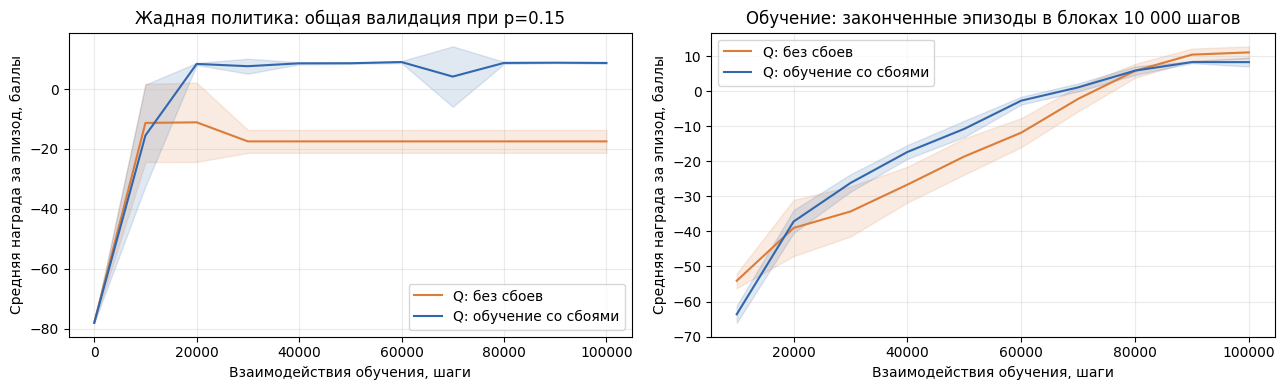

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
episodes["bin"] = ((episodes["step"] - 1) // CFG["checkpoint_every"] + 1) * CFG["checkpoint_every"]
training_bins = episodes.groupby(["condition", "seed", "bin"])["return"].mean().reset_index()

for condition in CFG["train_slip"]:
    validation = checkpoints.query("condition == @condition").groupby("step")["validation_return"].agg(["mean", "std"])
    training = training_bins.query("condition == @condition").groupby("bin")["return"].agg(["mean", "std"])
    for ax, frame in zip(axes, [validation, training]):
        x = frame.index.to_numpy()
        ax.plot(x, frame["mean"], label=LABELS[condition], color=COLORS[condition])
        ax.fill_between(x, frame["mean"] - frame["std"], frame["mean"] + frame["std"],
                        color=COLORS[condition], alpha=0.15)
        ax.set(xlabel="Взаимодействия обучения, шаги", ylabel="Средняя награда за эпизод, баллы")
        ax.legend()
axes[0].set_title("Жадная политика: общая валидация при p=0.15")
axes[1].set_title("Обучение: законченные эпизоды в блоках 10 000 шагов")
fig.tight_layout()
fig.savefig(OUT / "learning.png", dpi=150)
plt.show()

Линии - среднее по пяти seed обучения; полоса - одно выборочное стандартное
отклонение этих пяти средних, без интерпретации как доверительного интервала.
Слева одинаковая динамика оценки для обоих агентов. Справа награда с исследованием
действий в разных обучающих условиях, поэтому её нельзя напрямую использовать
для вывода о превосходстве одного агента.

## 6. Замороженные политики на тестовых эпизодах

Здесь используются только последние таблицы Q. Уровни 0.30 и 0.40 выше обучающего
шума обоих вариантов. Помимо двух агентов оцениваются три эвристики; для них нет
seed обучения. Их нельзя искусственно размножать пять раз и считать независимыми
обученными моделями.

In [8]:
test_frames = []
policies = [(condition, seed, models[f"{condition}_{seed}"])
            for condition in CFG["train_slip"] for seed in CFG["train_seeds"]]
policies += [(name, -1, name) for name in ["random", "shortest", "safe"]]

for condition, train_seed, policy in policies:
    for slip in CFG["test_slip"]:
        for group_id, (start_group, starts) in enumerate(STARTS.items()):
            frame = evaluate(policy, slip, starts, CFG["test_seed_base"] + group_id * 10000,
                             CFG["episodes_per_start"])
            test_frames.append(frame.assign(condition=condition, train_seed=train_seed,
                                             slip=slip, start_group=start_group))

test = pd.concat(test_frames, ignore_index=True)
assert (test["success"] + test["hazard"] + test["timeout"]).eq(1).all()
assert len(test) == len(policies) * len(CFG["test_slip"]) * len(STARTS) * 3 * CFG["episodes_per_start"]
by_seed = test.groupby(["condition", "train_seed", "slip", "start_group"])[METRICS].mean().reset_index()
summary = by_seed.groupby(["condition", "slip", "start_group"])[METRICS].agg(["mean", "std"])
test.to_csv(OUT / "test_episodes.csv", index=False)
by_seed.to_csv(OUT / "metrics_by_seed.csv", index=False)
summary.to_csv(OUT / "summary.csv")

In [9]:
# Таблица хранит средние всех эпизодов; разброс по seed показан на графиках и ниже.
table = by_seed.groupby(["condition", "slip", "start_group"])[METRICS].mean().reset_index()
selected = table[table["slip"].isin([0.0, 0.15, CFG["primary_test_slip"]])].copy()
selected["condition"] = selected["condition"].map(LABELS)
selected["start_group"] = selected["start_group"].map(START_LABELS)
display(selected.rename(columns={"condition": "Стратегия", "slip": "p сбоя",
    "start_group": "Старты", "return": "Награда, баллы", "success": "Доставка, доля",
    "hazard": "Авария, доля", "timeout": "Лимит, доля", "length": "Шагов",
    "adjacent_fraction": "Рядом с опасностью, доля"}).round(3))

,Стратегия,p сбоя,Старты,"Награда, баллы","Доставка, доля","Авария, доля","Лимит, доля",Шагов,"Рядом с опасностью, доля"
0,Q: без сбоев,0.00,Старты обучения,18.333,1.000,0.000,0.000,11.667,0.612
1,Q: без сбоев,0.00,Другие старты,16.667,1.000,0.000,0.000,13.333,0.225
6,Q: без сбоев,0.15,Старты обучения,-13.220,0.600,0.400,0.000,11.220,0.501
7,Q: без сбоев,0.15,Другие старты,-10.267,0.683,0.317,0.000,14.933,0.270
10,Q: без сбоев,0.30,Старты обучения,-31.043,0.367,0.633,0.000,10.377,0.410
11,Q: без сбоев,0.30,Другие старты,-37.923,0.353,0.647,0.000,16.190,0.235
14,Q: обучение со сбоями,0.00,Старты обучения,10.600,0.933,0.000,0.067,17.400,0.000
15,Q: обучение со сбоями,0.00,Другие старты,16.667,1.000,0.000,0.000,13.333,0.000
20,Q: обучение со сбоями,0.15,Старты обучения,11.983,0.987,0.013,0.000,16.950,0.033
21,Q: обучение со сбоями,0.15,Другие старты,12.353,1.000,0.000,0.000,17.647,0.020


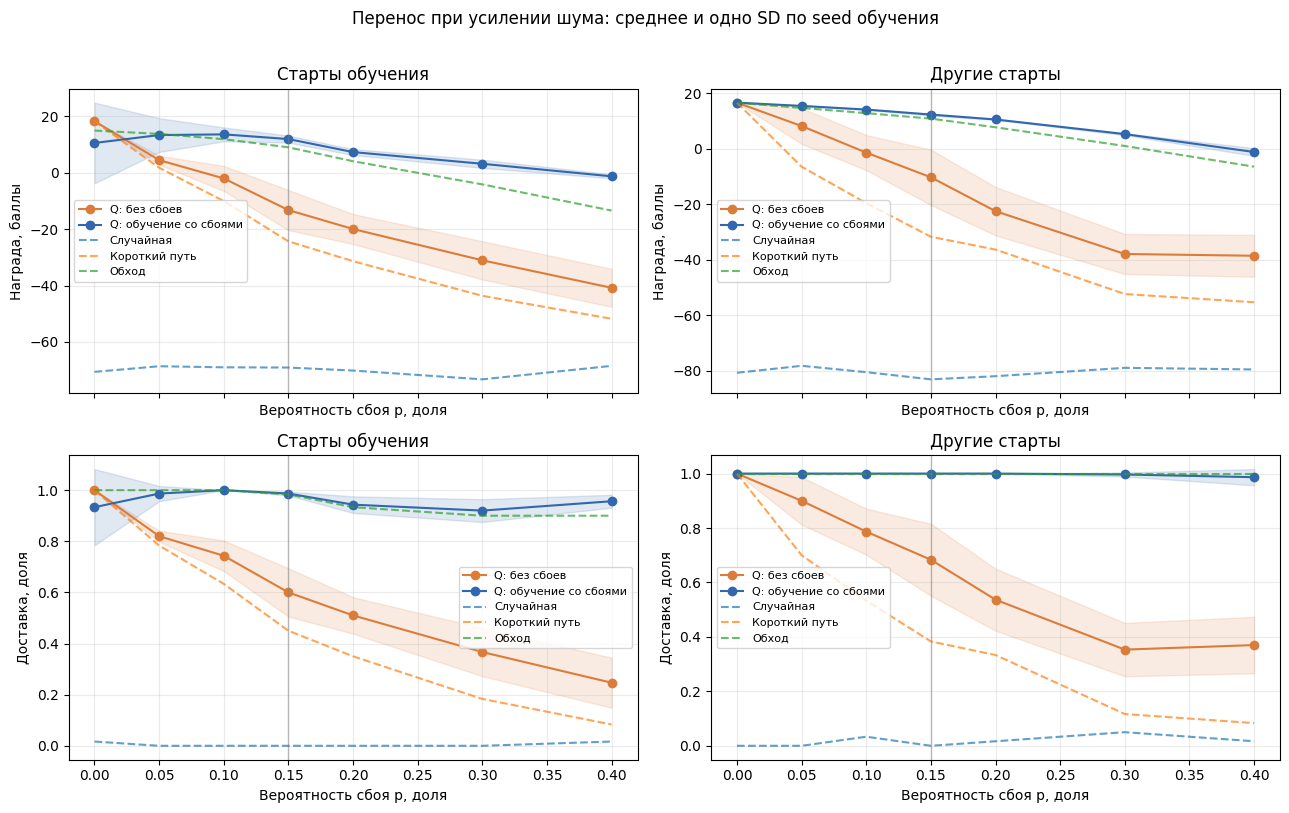

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
for col, start_group in enumerate(STARTS):
    for row, metric in enumerate(["return", "success"]):
        ax = axes[row, col]
        for condition in LABELS:
            frame = by_seed.query("condition == @condition and start_group == @start_group")
            stats = frame.groupby("slip")[metric].agg(["mean", "std"])
            if condition in COLORS:
                ax.plot(stats.index, stats["mean"], "o-", color=COLORS[condition], label=LABELS[condition])
                ax.fill_between(stats.index, stats["mean"] - stats["std"],
                                stats["mean"] + stats["std"], color=COLORS[condition], alpha=0.15)
            else:
                ax.plot(stats.index, stats["mean"], "--", alpha=0.7, label=LABELS[condition])
        ax.axvline(0.15, color="gray", alpha=0.5, linewidth=1)
        ax.set(title=START_LABELS[start_group], xlabel="Вероятность сбоя p, доля",
               ylabel="Награда, баллы" if metric == "return" else "Доставка, доля")
        ax.legend(fontsize=8)
fig.suptitle("Перенос при усилении шума: среднее и одно SD по seed обучения", y=1.01)
fig.tight_layout()
fig.savefig(OUT / "robustness.png", dpi=150, bbox_inches="tight")
plt.show()

Для эвристик показана одна оценка на 60 эпизодах в каждом условии, без полосы
разброса по seed обучения. Доли доставок в таблицах лежат в [0, 1]; границы полосы
«среднее +/- SD» на графике могут выходить за этот интервал. Вертикальная линия -
уровень шума обучения `noisy`.

In [11]:
primary = by_seed[by_seed["slip"].eq(CFG["primary_test_slip"]) & by_seed["train_seed"].ne(-1)]
primary = primary.groupby(["condition", "train_seed"])[METRICS].mean().reset_index()
paired = primary.pivot(index="train_seed", columns="condition", values=["return", "success"])
differences = pd.DataFrame({"Разность наград, баллы": paired["return"]["noisy"] - paired["return"]["dry"],
                            "Разность доставок, п.п.": 100 * (paired["success"]["noisy"] - paired["success"]["dry"])})
display(differences.round(3))
display(differences.agg(["mean", "std", "min", "max"]).round(3))
differences.to_csv(OUT / "paired_differences.csv")

,"Разность наград, баллы","Разность доставок, п.п."
train_seed,,
11,33.558,55.000
23,46.250,68.333
37,44.983,68.333
53,32.983,51.667
71,35.958,55.833


,"Разность наград, баллы","Разность доставок, п.п."
mean,38.747,59.833
std,6.386,7.914
min,32.983,51.667
max,46.250,68.333


Это парное сравнение одинаковых seed обучения и тестовых воздействий. Единица
повторения для разброса - обученный агент, а не каждый отдельный эпизод.
Пять seed характеризуют чувствительность к обучению, но не устраняют неопределённость
из-за конечного набора тестовых эпизодов. Ни SD, ни одинаковый знак разностей сами
по себе не являются доказательством статистической значимости.

При p=0 повторные эпизоды из одной позиции у детерминированной политики
совпадают: 20 повторов сохраняют единый протокол, но не добавляют независимой
информации. Разброс на графиках относится к пяти разным обученным агентам.

## 7. Поведение и ошибки

Для визуализации заранее выбраны первый seed обучения, первый тестовый seed и
старт `(6, 0)`. Показаны отсутствие шума и основной стресс-тест. Это иллюстрации
механизма, а не основание для общего вывода вместо агрегированных метрик.

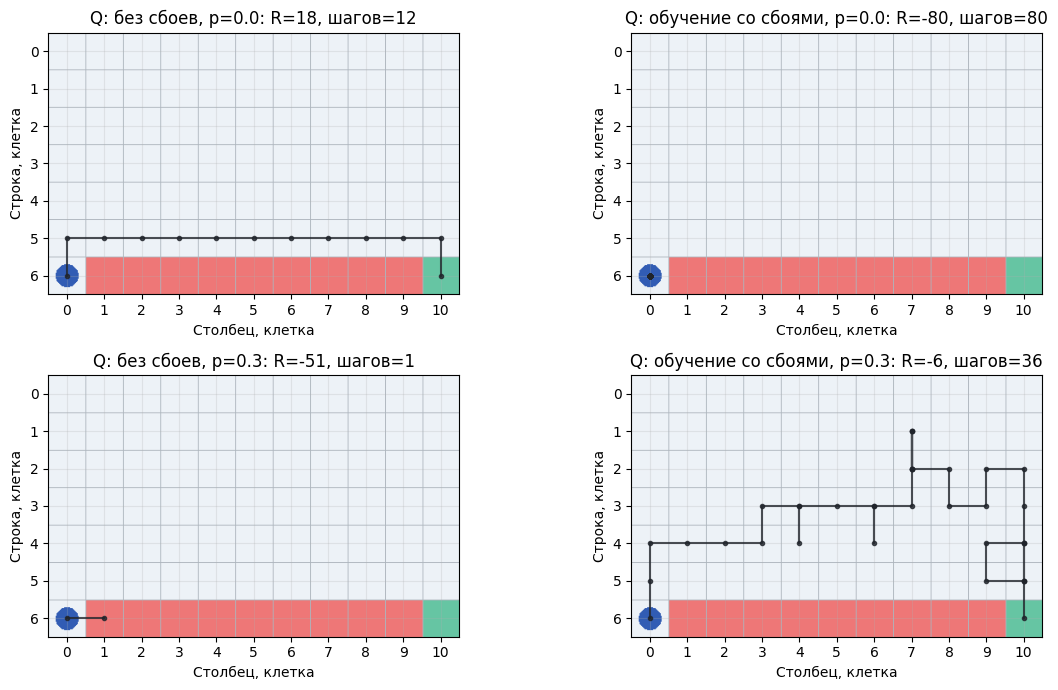

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
seed = CFG["train_seeds"][0]
for row, slip in enumerate([0.0, CFG["primary_test_slip"]]):
    for col, condition in enumerate(CFG["train_slip"]):
        q = models[f"{condition}_{seed}"]
        metrics, path = run_episode(q, slip, (6, 0), CFG["test_seed_base"])
        env.reset(options={"start": (6, 0)})
        ax = axes[row, col]
        ax.imshow(env.render(), extent=(-0.5, 10.5, 6.5, -0.5))
        yy, xx = np.array(path).T
        ax.plot(xx, yy, "o-", color="#20242b", markersize=3, alpha=0.8)
        ax.set(title=f"{LABELS[condition]}, p={slip}: R={metrics['return']:.0f}, шагов={metrics['length']}",
               xlabel="Столбец, клетка", ylabel="Строка, клетка", xticks=range(11), yticks=range(7))
fig.tight_layout()
fig.savefig(OUT / "trajectories.png", dpi=150)
plt.show()

Слева: Q: без сбоев: R=-51; справа: Q: обучение со сбоями: R=-6


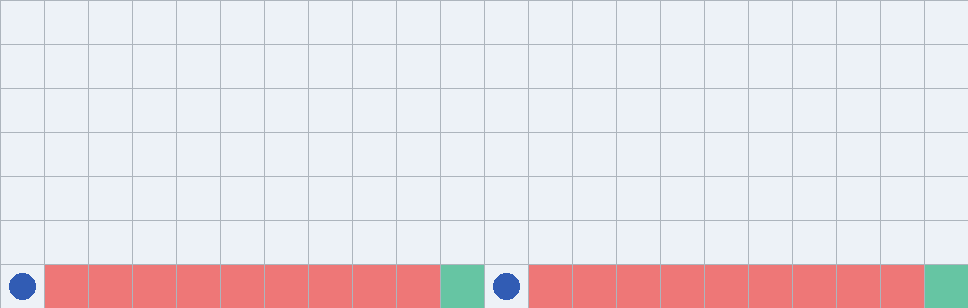

In [13]:
# Общая анимация двух политик при одном заранее заданном воздействии.
paths, descriptions = [], []
for condition in CFG["train_slip"]:
    metrics, path = run_episode(models[f"{condition}_{seed}"], CFG["primary_test_slip"],
                               (6, 0), CFG["test_seed_base"] + CFG["animation_episode"])
    paths.append(path)
    descriptions.append(f"{LABELS[condition]}: R={metrics['return']:.0f}")

frames = []
for step in range(max(map(len, paths))):
    panels = []
    for path in paths:
        env.position = path[min(step, len(path) - 1)]
        panels.append(PILImage.fromarray(env.render()))
    canvas = PILImage.new("RGB", (panels[0].width * 2, panels[0].height))
    for i, panel in enumerate(panels):
        canvas.paste(panel, (i * panel.width, 0))
    frames.append(canvas)
frames[0].save(OUT / "behavior.gif", save_all=True, append_images=frames[1:], duration=220, loop=0)
print("Слева: " + descriptions[0] + "; справа: " + descriptions[1])
display(Image(filename=str(OUT / "behavior.gif")))

In [14]:
# Длина успешного пути не смешивается с короткими аварийными эпизодами.
stress = test[test["slip"].eq(CFG["primary_test_slip"])].copy()
behavior = stress.groupby("condition").agg(
    success=("success", "mean"), hazard=("hazard", "mean"), timeout=("timeout", "mean"),
    adjacent_fraction=("adjacent_fraction", "mean"))
behavior["successful_length"] = stress[stress["success"].eq(1)].groupby("condition")["length"].mean()
display(behavior.rename(index=LABELS).round(3))
behavior.to_csv(OUT / "behavior_metrics.csv")

failures = stress[stress["success"].eq(0)].sort_values(
    ["condition", "train_seed", "start_group", "episode_seed"]).groupby("condition").head(3)
display(failures[["condition", "train_seed", "start_group", "start", "episode_seed",
                  "hazard", "timeout", "length", "return"]])
failures.to_csv(OUT / "failure_examples.csv", index=False)

,success,hazard,timeout,adjacent_fraction,successful_length
condition,,,,,
Q: без сбоев,0.360,0.640,0.000,0.323,18.514
Q: обучение со сбоями,0.958,0.042,0.000,0.069,23.311
Случайная,0.025,0.767,0.208,0.105,66.333
Обход,0.950,0.050,0.000,0.010,28.930
Короткий путь,0.150,0.850,0.000,0.477,16.778


,condition,train_seed,start_group,start,episode_seed,hazard,timeout,length,return
600,dry,11,familiar,"(6, 0)",2000000,1,0,1,-51.0
603,dry,11,familiar,"(6, 0)",2000003,1,0,6,-56.0
605,dry,11,familiar,"(6, 0)",2000005,1,0,3,-53.0
5640,noisy,23,familiar,"(6, 0)",2000000,1,0,1,-51.0
5648,noisy,23,familiar,"(6, 0)",2000008,1,0,1,-51.0
5651,noisy,23,familiar,"(6, 0)",2000011,1,0,1,-51.0
9000,random,-1,familiar,"(6, 0)",2000000,1,0,24,-74.0
9001,random,-1,familiar,"(6, 0)",2000001,1,0,1,-51.0
9002,random,-1,familiar,"(6, 0)",2000002,1,0,1,-51.0
10680,safe,-1,familiar,"(6, 0)",2000000,1,0,1,-51.0


In [15]:
# Разбор обнаруженного таймаута: действие у нижнего левого угла.
action_names = ["вверх", "вправо", "вниз", "влево"]
wall_records = []
for train_seed in CFG["train_seeds"]:
    q = models[f"noisy_{train_seed}"]
    action = int(q[6 * WarehouseEnv.cols].argmax())
    metrics, _ = run_episode(q, 0.0, (6, 0), CFG["test_seed_base"])
    wall_records.append({"seed": train_seed, "action": action_names[action],
                         "success_without_noise": metrics["success"],
                         "steps_without_noise": metrics["length"]})
wall_analysis = pd.DataFrame(wall_records)
display(wall_analysis)
wall_analysis.to_csv(OUT / "wall_analysis.csv", index=False)

,seed,action,success_without_noise,steps_without_noise
0,11,влево,0,80
1,23,вверх,1,14
2,37,вверх,1,14
3,53,вверх,1,14
4,71,вверх,1,14


Авария обычно связана с входом в нижнюю опасную строку; таймаут - с блужданием
или чрезмерной осторожностью. Метрика соседства считает долю **предшествующих
действию** позиций `(5, 1)...(5, 9)` в каждом эпизоде и затем усредняется по эпизодам.
Она описывает стратегию, но не заменяет измеренную долю аварий: при сильном шуме
опасный переход возможен и вне обычного короткого маршрута.

У нижнего левого угла действие «влево» упирается в стену. При $p>0$ случайный
поворот вверх с вероятностью $p/2$ позволяет выйти из угла; при $p=0$ такая
детерминированная политика никогда не выйдет. Таблица выше проверяет этот механизм
для всех пяти обученных агентов. Это зависимость от шума как от ресурса движения,
а не только выбор длинного безопасного маршрута. Разбор проведён после теста;
он не использовался для изменения протокола или переобучения.

## 8. Ответ на вопрос и ограничения

Следующая ячейка формирует численный вывод из фактического теста, без заранее
заданного утверждения о подтверждении гипотезы. Положительная разность одновременно
по награде и доставкам поддерживает гипотезу в выбранных условиях; малые и нестабильные
различия требуют осторожной интерпретации.

In [16]:
reward_delta = differences["Разность наград, баллы"]
success_delta = differences["Разность доставок, п.п."]
clean = by_seed[by_seed["slip"].eq(0) & by_seed["train_seed"].ne(-1)]
clean = clean.groupby("condition")[METRICS].mean()
direction = ("поддерживают гипотезу" if reward_delta.mean() > 0 and success_delta.mean() > 0
             else "не поддерживают гипотезу по двум основным показателям одновременно")
conclusion = f'''При p={CFG['primary_test_slip']:.2f} обучение со сбоями изменило награду
на {reward_delta.mean():+.2f} балла (SD между seed {reward_delta.std():.2f}; диапазон
{reward_delta.min():+.2f}...{reward_delta.max():+.2f}) и долю доставок на
{success_delta.mean():+.2f} п.п. Средние результаты {direction}.
Разность награды положительна у {(reward_delta > 0).sum()} из {len(reward_delta)} пар seed.
Без сбоев изменение награды составляет {clean.loc['noisy', 'return'] - clean.loc['dry', 'return']:+.2f}
балла, а средней длины эпизода - {clean.loc['noisy', 'length'] - clean.loc['dry', 'length']:+.2f} шага.
Сравнение относится к последним политикам при одинаковом бюджете; промежуточные
результаты не использовались для выбора победителя.'''
display(Markdown(conclusion))
(OUT / "conclusion.md").write_text(conclusion, encoding="utf-8")

При p=0.30 обучение со сбоями изменило награду
на +38.75 балла (SD между seed 6.39; диапазон
+32.98...+46.25) и долю доставок на
+59.83 п.п. Средние результаты поддерживают гипотезу.
Разность награды положительна у 5 из 5 пар seed.
Без сбоев изменение награды составляет -3.87
балла, а средней длины эпизода - +2.87 шага.
Сравнение относится к последним политикам при одинаковом бюджете; промежуточные
результаты не использовались для выбора победителя.

453

In [17]:
stress_means = stress.groupby("condition")[METRICS].mean()
wall_failures = int(wall_analysis["success_without_noise"].eq(0).sum())
mechanism = f'''При основном уровне шума доля позиций рядом с опасностью снизилась
с {100 * stress_means.loc['dry', 'adjacent_fraction']:.2f}% до
{100 * stress_means.loc['noisy', 'adjacent_fraction']:.2f}%, а доля аварий - с
{100 * stress_means.loc['dry', 'hazard']:.2f}% до {100 * stress_means.loc['noisy', 'hazard']:.2f}%.
Это согласуется с объяснением через более безопасный маршрут. При этом у {wall_failures}
из {len(wall_analysis)} агентов обнаружен таймаут из угла без шума: цена устойчивости
включает зависимость от случайного движения, а не только несколько лишних шагов.
Для сравнения: случайная стратегия доставляет {100 * stress_means.loc['random', 'success']:.2f}%
грузов; ручной обход - {100 * stress_means.loc['safe', 'success']:.2f}%.
Обученный со сбоями агент имеет {100 * stress_means.loc['noisy', 'success']:.2f}% доставок,
но разница с ручным обходом мала и не даёт основания заявлять его надёжное превосходство.
Средняя длина успешных эпизодов: {behavior.loc['noisy', 'successful_length']:.2f} шага у
агента со сбоями и {behavior.loc['safe', 'successful_length']:.2f} у ручного обхода.'''
display(Markdown(mechanism))
with (OUT / "conclusion.md").open("a", encoding="utf-8") as file:
    file.write("\n\n" + mechanism)

При основном уровне шума доля позиций рядом с опасностью снизилась
с 32.26% до
6.87%, а доля аварий - с
64.00% до 4.17%.
Это согласуется с объяснением через более безопасный маршрут. При этом у 1
из 5 агентов обнаружен таймаут из угла без шума: цена устойчивости
включает зависимость от случайного движения, а не только несколько лишних шагов.
Для сравнения: случайная стратегия доставляет 2.50%
грузов; ручной обход - 95.00%.
Обученный со сбоями агент имеет 95.83% доставок,
но разница с ручным обходом мала и не даёт основания заявлять его надёжное превосходство.
Средняя длина успешных эпизодов: 23.31 шага у
агента со сбоями и 28.93 у ручного обхода.

**Объяснение и альтернативы.** Шум меняет ожидаемую стоимость прохода рядом с опасной
зоной: более длинный путь может уменьшать потери груза. Проверять это объяснение
нужно по траекториям и метрике соседства, сопоставляя их с авариями. Различия между
seed также могут объясняться покрытием состояний, остаточным исследованием действий
и постоянным шагом обучения. Стены подавляют некоторые ошибочные действия, поэтому
устойчивость может возникать за счёт движения вдоль границы, а не только большого
расстояния до опасности. Превосходство над случайной стратегией показывает эффект
обучения, но не доказывает превосходства над любой вручную заданной политикой.

**Ограничения.** Одна небольшая карта, известные точные координаты, независимые
перпендикулярные сбои, фиксированная функция награды, пять seed и 60 эпизодов на
условие ограничивают переносимость вывода. В среднем по двум наборам стартов
заданы равные веса, которые могут отличаться от реального распределения заказов.
Тестовые seed общие между агентами, поэтому эпизоды нельзя трактовать как полностью
независимые повторения обучения. Внешний лимит в 80 шагов ограничивает метрику,
хотя Q-learning оценивает продолжение после обрыва. Табличный метод не переносится
на новую карту без обучения, а отсутствие подбора гиперпараметров не гарантирует
исчерпания возможностей обоих условий.

Далее имело бы смысл проверить другие карты, коррелированные сбои и иную цену
аварии. Эти эксперименты здесь не выполняются.

## 9. Сохранение воспроизводимого результата

Ноутбук сохраняет таблицы Q, все тестовые эпизоды, историю обучения, графики,
анимацию и численный вывод в `results/`. Файл `pip-freeze.txt` - снимок фактического
окружения с исключением локальных editable-проектов; для установки используется
компактный `requirements.txt`. Исходное условие не изменяется.

In [18]:
(OUT / "experiment_config.json").write_text(json.dumps(CFG, ensure_ascii=False, indent=2), encoding="utf-8")
freeze = subprocess.check_output([sys.executable, "-m", "pip", "freeze", "--exclude-editable"], text=True)
(OUT / "pip-freeze.txt").write_text(freeze, encoding="utf-8")
provenance = {"python": platform.python_version(), "platform": platform.platform(),
              "seconds_total": time.perf_counter() - experiment_started,
              "environment_sha256": hashlib.sha256((PROJECT / "warehouse_env.py").read_bytes()).hexdigest(),
              "config_sha256": hashlib.sha256((PROJECT / "experiment_config.json").read_bytes()).hexdigest(),
              "training_transitions_total": len(CFG["train_seeds"]) * len(CFG["train_slip"]) * CFG["train_steps"],
              "test_episodes_total": len(test)}
(OUT / "provenance.json").write_text(json.dumps(provenance, indent=2), encoding="utf-8")
print(f"Обучение: {timings['seconds'].sum():.1f} с; вся работа: {provenance['seconds_total']:.1f} с.")
print(f"Переходов обучения: {provenance['training_transitions_total']:,}; тестовых эпизодов: {len(test):,}.")

Обучение: 47.5 с; вся работа: 61.3 с.
Переходов обучения: 1,000,000; тестовых эпизодов: 10,920.


## Источники

- [Watkins, Dayan (1992), Q-learning](https://www.gatsby.ucl.ac.uk/~dayan/papers/cjch.pdf) - алгоритм табличного обучения.
- [Gymnasium: создание собственной среды](https://gymnasium.farama.org/introduction/create_custom_env/) - интерфейс `reset`, `step` и воспроизводимость.
- [Farama: terminated и truncated](https://farama.org/Gymnasium-Terminated-Truncated-Step-API) - продолжение оценки при внешнем ограничении времени.

Карта и исследовательский протокол реализованы для этой работы; идея опасной границы
родственна учебной задаче Cliff Walking, но используются собственная стохастическая
динамика привода, несколько начальных распределений и отдельная проверка переноса.